# Experiment 4 — MovieLens random pairs: robustness across the real-data pair distribution

Figures per `docs/experiments.md`, Experiment 4 "Figures" subsection. This notebook only loads `results/exp4_1/results.parquet`, `results/exp4_2/results.parquet`, `results/exp4_3/results.parquet` and plots — it never recomputes (see CLAUDE.md and `docs/experiments.md` §0.4). Run `python -m scripts.run_experiment4` (or `SMOKE_TEST=1 python -m scripts.run_experiment4` first) to generate them.

**Note:** design revised twice after real smoke-test evidence (see `docs/experiments.md`'s Experiment 4 "REVISION HISTORY") — `unif-kkm-full` dropped, `budget_cap` raised to 20000, `exp4_1`/`exp4_2`'s thresholds changed, `exp4_3` dropped then re-added at a looser threshold (0.2, not the original 0.1). This notebook has not yet been run against the real (100-rep) results under this latest config — only smoke-test-scale passes so far. Re-run once `results/exp4_*/results.parquet` reflect the real run.

Each version reports 6 algorithm rows per rep: `kabc`, `kabc-sg`, `acb`, `tas-fw`, and two `unif-kkm` variants (`unif-kkm-1x`/`unif-kkm-2x` = that same rep's kabc τ, ×1 or ×2, capped at `budget_cap` — see docs/experiments.md's "unif-kkm variants").

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from kabc.plotting import set_style, savefig, ALGO_ORDER, ALGO_COLORS, ALGO_LABELS

set_style()

VERSIONS = ["exp4_1", "exp4_2", "exp4_3"]
VERSION_TITLES = {
    "exp4_1": "exp4_1: tight gap, argmax MMD² (gap ≤ 0.1)",
    "exp4_2": "exp4_2: moderate gap, uniform (0.1 ≤ gap ≤ 0.5)",
    "exp4_3": "exp4_3: tight-ish gap, uniform (gap ≤ 0.2)",
}

dfs = {}
for version in VERSIONS:
    path = Path(f"../results/{version}/results.parquet")
    if not path.exists():
        raise FileNotFoundError(
            f"{path} not found. Run `python -m scripts.run_experiment4` (or with SMOKE_TEST=1) "
            "to generate it -- this notebook only plots existing results, it never recomputes them."
        )
    dfs[version] = pd.read_parquet(path)
    print(f"loaded {len(dfs[version])} rows from {path}")

dfs[VERSIONS[0]].head()

loaded 240 rows from ../results/exp4_1/results.parquet
loaded 240 rows from ../results/exp4_2/results.parquet
loaded 240 rows from ../results/exp4_3/results.parquet


,exp_id,version,algorithm,rep,seed,budget_cap,tau,stopped,wall_clock_seconds,partition,error,ari,n_iterations,movie_id_a,movie_id_b,title_a,title_b,mean_a,mean_b,mmd2_ab
0,4,exp4_1,kabc,0,4000100,20000,3112,True,0.534389,"[0, 0, 0, 0, 1, 1, 1, 1]",0,1.000000,4,2959,1674,Fight Club (1999),Witness (1985),4.077188,3.996176,0.040454
1,4,exp4_1,kabc-sg,0,4000101,20000,13832,False,2.981346,"[0, 0, 0, 1, 2, 3, 3, 3]",1,0.533333,7,2959,1674,Fight Club (1999),Witness (1985),4.077188,3.996176,0.040454
2,4,exp4_1,acb,0,4000102,20000,19988,False,0.929096,"[0, 0, 0, 0, 0, 0, 0, 0]",1,0.000000,9,2959,1674,Fight Club (1999),Witness (1985),4.077188,3.996176,0.040454
3,4,exp4_1,tas-fw,0,4000103,20000,12931,True,547.734856,"[0, 0, 0, 0, 1, 1, 1, 1]",0,1.000000,12923,2959,1674,Fight Club (1999),Witness (1985),4.077188,3.996176,0.040454
4,4,exp4_1,unif-kkm-1x,0,4000104,3112,3112,True,0.181348,"[0, 0, 0, 0, 1, 1, 1, 1]",0,1.000000,0,2959,1674,Fight Club (1999),Witness (1985),4.077188,3.996176,0.040454


## Figures: three bar plots (ARI, τ, wall-clock/rep), each with all 3 versions × 6 algorithms

One bar plot per metric, not one figure per version: each plot has 18 bars grouped into 3 sets of 6 (one set per version: `exp4_1`, `exp4_2`, `exp4_3`), each set showing all 6 algorithm rows (`kabc`, `kabc-sg`, `acb`, `tas-fw`, `unif-kkm-1x`, `unif-kkm-2x`) side by side. Bar height = mean over reps; error bar = standard deviation over reps (not standard error — the spread itself is the point, since each rep is also a different randomly-sampled movie pair, not just different pull-noise on a fixed instance).

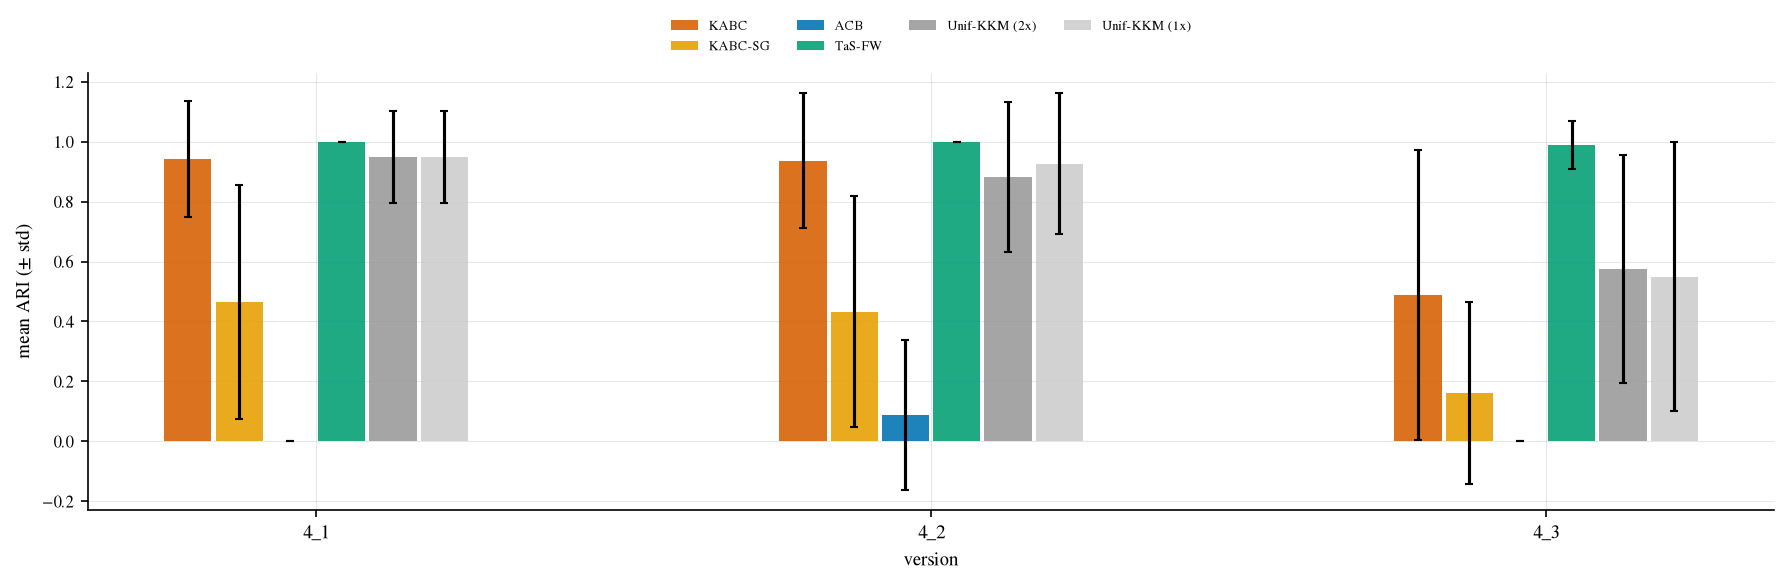

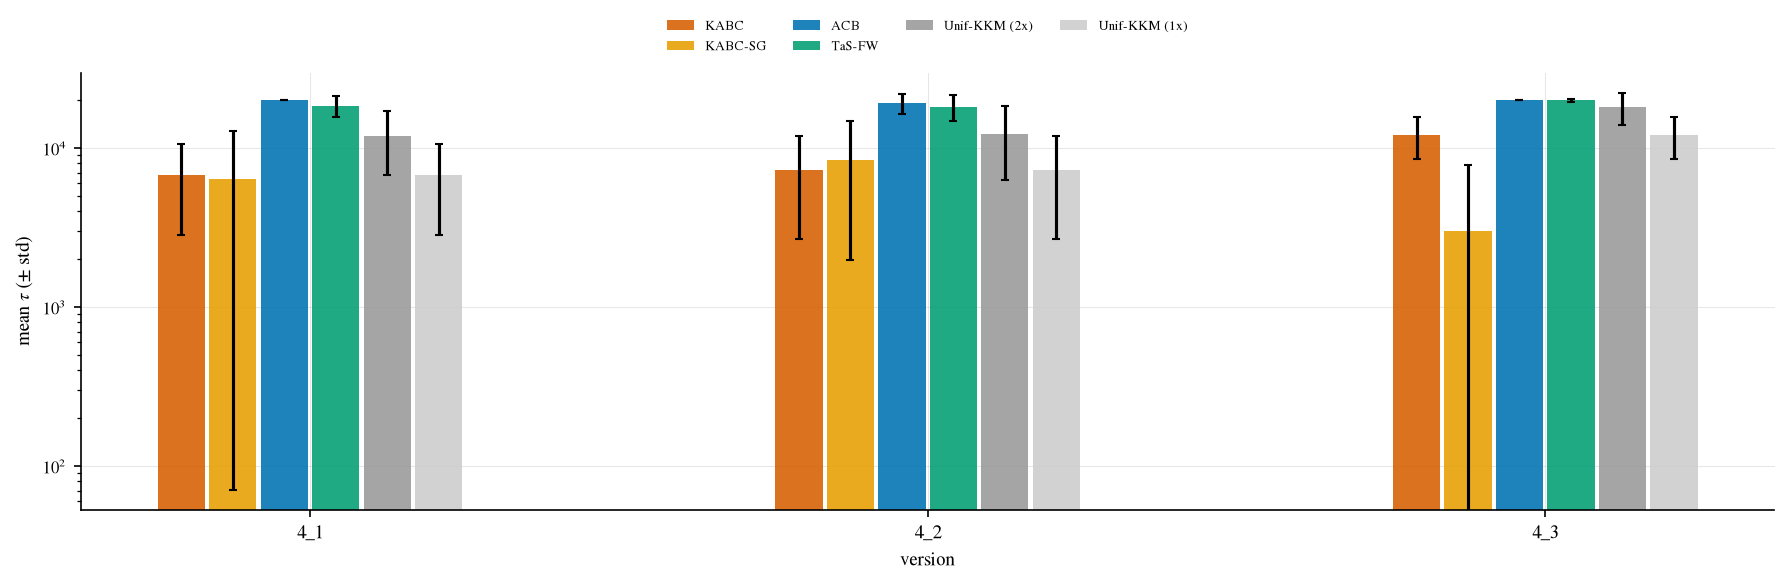

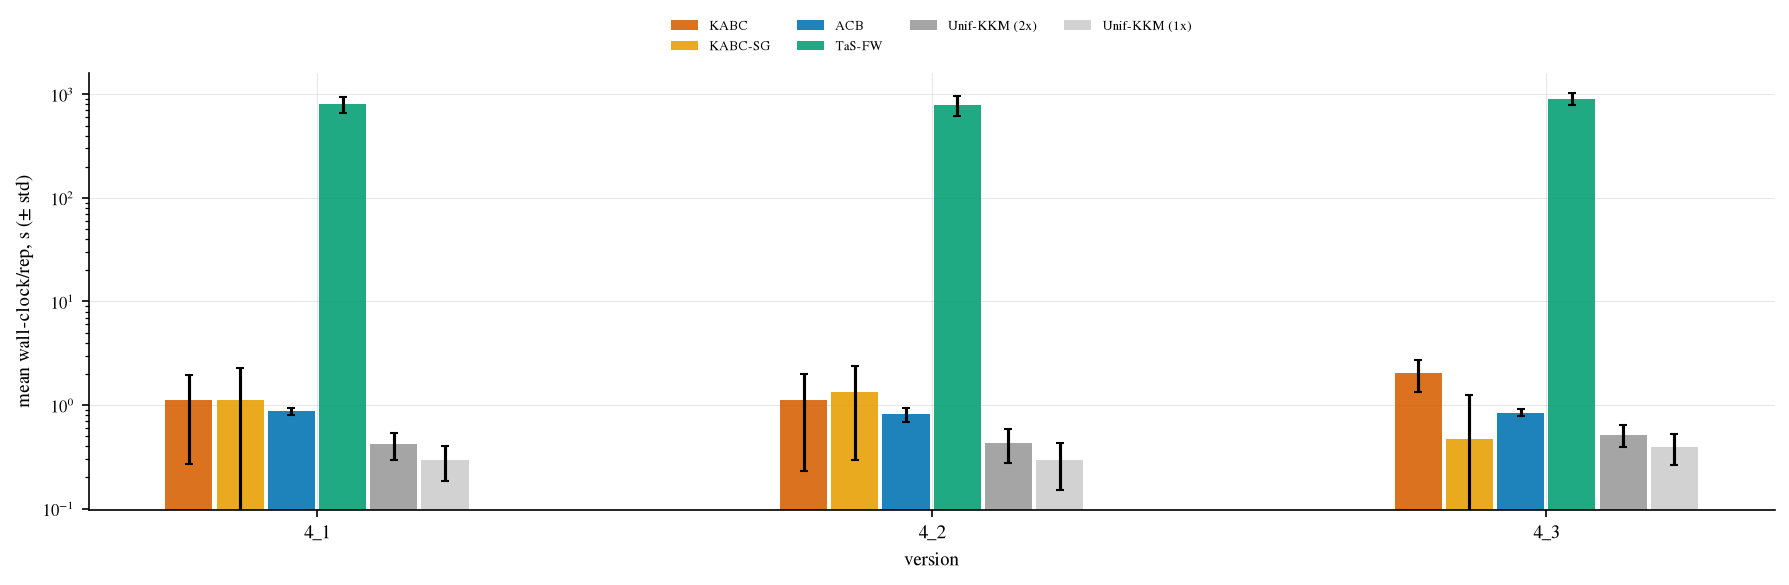

In [2]:
ALGOS = [a for a in ALGO_ORDER if a in dfs[VERSIONS[0]]["algorithm"].unique()]
assert len(ALGOS) == 6, f"expected 6 algorithm rows, got {len(ALGOS)}: {ALGOS}"

VERSION_SHORT = {"exp4_1": "4_1", "exp4_2": "4_2", "exp4_3": "4_3"}


def grouped_bar_plot(metric_col: str, ylabel: str, fig_name: str, log_scale: bool = False):
    """One bar plot: 3 sets (versions) x 6 bars (algorithms) = 18 bars total,
    grouped with a visible gap between sets so the 3 versions read as
    distinct clusters, not one continuous row of 18 bars."""
    n_algo = len(ALGOS)
    bar_width = 0.8 / n_algo
    group_gap = 0.6  # extra spacing between each version's cluster of 6 bars

    fig, ax = plt.subplots(figsize=(12, 4))
    xtick_positions, xtick_labels = [], []
    for v_idx, version in enumerate(VERSIONS):
        df = dfs[version]
        group_center = v_idx * (1.0 + group_gap)
        for a_idx, algo in enumerate(ALGOS):
            sub = df[df["algorithm"] == algo]
            mean = sub[metric_col].mean()
            std = sub[metric_col].std()
            x = group_center + (a_idx - (n_algo - 1) / 2) * bar_width
            ax.bar(x, mean, yerr=std, width=bar_width * 0.92, capsize=2,
                   color=ALGO_COLORS[algo], alpha=0.88,
                   label=ALGO_LABELS[algo] if v_idx == 0 else None)
        xtick_positions.append(group_center)
        xtick_labels.append(VERSION_SHORT[version])

    ax.set_xticks(xtick_positions)
    ax.set_xticklabels(xtick_labels, fontsize=9)
    ax.set_xlabel("version")
    ax.set_ylabel(ylabel)
    if log_scale:
        ax.set_yscale("log")
    ax.legend(fontsize=6.5, frameon=False, ncol=4, loc="upper center", bbox_to_anchor=(0.5, 1.15))
    fig.tight_layout()
    savefig(fig, fig_name, fig_dir="../results/figures")
    plt.show()


grouped_bar_plot("ari", "mean ARI (± std)", "exp4_fig1_ari_bars")
grouped_bar_plot("tau", r"mean $\tau$ (± std)", "exp4_fig2_tau_bars", log_scale=True)
grouped_bar_plot("wall_clock_seconds", "mean wall-clock/rep, s (± std)", "exp4_fig3_wallclock_bars", log_scale=True)

## Summary tables: exact mean ± std per algorithm, per version

Printed (not just plotted) so the restricted-budget-style claims in the write-up can cite exact numbers, same convention as notebook 01's restricted-budget breakdowns.

In [3]:
for version in VERSIONS:
    df = dfs[version]
    algos_present = [a for a in ALGO_ORDER if a in df["algorithm"].unique()]
    rows = []
    for a in algos_present:
        sub = df[df["algorithm"] == a]
        rows.append({
            "algorithm": ALGO_LABELS[a],
            "mean_tau": sub["tau"].mean(),
            "std_tau": sub["tau"].std(),
            "mean_ari": sub["ari"].mean(),
            "std_ari": sub["ari"].std(),
            "mean_wall_clock_s": sub["wall_clock_seconds"].mean(),
            "std_wall_clock_s": sub["wall_clock_seconds"].std(),
            "frac_stopped": sub["stopped"].mean(),
        })
    print(f"=== {version} ===")
    display(pd.DataFrame(rows))

=== exp4_1 ===


,algorithm,mean_tau,std_tau,mean_ari,std_ari,mean_wall_clock_s,std_wall_clock_s,frac_stopped
0,KABC,6748.600,3922.431433,0.942134,0.194082,1.115502,0.845883,0.975
1,KABC-SG,6425.000,6354.072177,0.464083,0.390513,1.113008,1.156234,0.650
2,ACB,19993.750,4.578377,0.000000,0.000000,0.866947,0.067805,0.000
3,TaS-FW,18448.175,2759.222790,1.000000,0.000000,798.231048,142.871085,0.300
4,Unif-KKM (2x),11964.400,5161.145554,0.949485,0.153477,0.419066,0.121427,1.000
5,Unif-KKM (1x),6748.600,3922.431433,0.949485,0.153477,0.294682,0.111414,1.000


=== exp4_2 ===


,algorithm,mean_tau,std_tau,mean_ari,std_ari,mean_wall_clock_s,std_wall_clock_s,frac_stopped
0,KABC,7296.40,4620.105520,0.936746,0.225524,1.124409,0.891217,0.900
1,KABC-SG,8425.40,6461.503170,0.432934,0.386573,1.332814,1.036905,0.550
2,ACB,19152.55,2676.036219,0.089052,0.250631,0.812931,0.128476,0.175
3,TaS-FW,18165.90,3281.981061,1.000000,0.000000,789.158034,170.419863,0.350
4,Unif-KKM (2x),12293.60,6031.975025,0.881352,0.250088,0.433659,0.157437,1.000
5,Unif-KKM (1x),7296.40,4620.105520,0.926680,0.236029,0.293173,0.140887,1.000


=== exp4_3 ===


,algorithm,mean_tau,std_tau,mean_ari,std_ari,mean_wall_clock_s,std_wall_clock_s,frac_stopped
0,KABC,12127.00,3538.254386,0.487619,0.484258,2.038592,0.713597,0.525
1,KABC-SG,3007.40,4846.559958,0.160045,0.303625,0.473883,0.776285,0.875
2,ACB,19992.50,5.237929,0.000000,0.000000,0.846719,0.067573,0.000
3,TaS-FW,19919.85,506.913109,0.987371,0.079872,908.278510,124.373796,0.025
4,Unif-KKM (2x),18122.80,4102.303463,0.573963,0.380082,0.517290,0.127249,1.000
5,Unif-KKM (1x),12127.00,3538.254386,0.549684,0.448996,0.397490,0.131354,1.000
